In [1]:
import json

path = "Securities&Futures.ipynb"
with open(path, encoding="utf-8") as f:
    nb = json.load(f)

nb.get("metadata", {}).pop("widgets", None)
for cell in nb.get("cells", []):
    cell.get("metadata", {}).pop("widgets", None)

with open(path, "w", encoding="utf-8") as f:
    json.dump(nb, f, indent=1, ensure_ascii=False)

In [2]:
import pandas as pd
import mplfinance as mpf
import mplfinance as fplt
import yfinance as yf
import matplotlib.pyplot as plt
import plotly
import plotly.graph_objects as go
import matplotlib.ticker as mtick
import numpy as np
from datetime import datetime
from dateutil.relativedelta import relativedelta
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')
import ta

In [3]:
# ==========================================
# Technical Analysis
# ==========================================
today = datetime.today()
twenty_yrs_ago = today - relativedelta(years=20)
ticker = "spy"
warren_buffet =yf.Ticker(ticker)
george_soros = warren_buffet.history(start=twenty_yrs_ago, end=today,interval='1d')
george_soros['SMA 50'] = george_soros['Close'].rolling(50, min_periods=1).mean()
george_soros['SMA 100'] = george_soros['Close'].rolling(100, min_periods=1).mean()
george_soros['SMA 200'] = george_soros['Close'].rolling(200, min_periods=1).mean()
george_soros['RSI'] = ta.momentum.RSIIndicator(george_soros['Close']).rsi()
macd = ta.trend.MACD(george_soros['Close'])
george_soros['MACD'] = macd.macd()
george_soros['MACD Signal'] = macd.macd_signal()

george_soros

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Capital Gains,SMA 50,SMA 100,SMA 200,RSI,MACD,MACD Signal
Date,,,,,,,,,,,,,,
2006-11-02 00:00:00-05:00,94.706394,95.053279,94.602333,94.893715,60693100,0.0,0.0,0.0,94.893715,94.893715,94.893715,NaN,NaN,NaN
2006-11-03 00:00:00-05:00,95.233693,95.316942,94.088968,94.727234,71346400,0.0,0.0,0.0,94.810474,94.810474,94.810474,NaN,NaN,NaN
2006-11-06 00:00:00-05:00,95.018583,95.934353,95.011639,95.795601,63303300,0.0,0.0,0.0,95.138850,95.138850,95.138850,NaN,NaN,NaN
2006-11-07 00:00:00-05:00,95.878867,96.420006,95.740115,96.163315,63318900,0.0,0.0,0.0,95.394966,95.394966,95.394966,NaN,NaN,NaN
2006-11-08 00:00:00-05:00,95.740158,96.468618,94.949261,96.371490,87517800,0.0,0.0,0.0,95.590271,95.590271,95.590271,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-26 00:00:00-04:00,762.250000,767.729980,761.630005,765.369995,31737800,0.0,0.0,0.0,766.717264,756.704029,724.408314,47.556801,-0.337682,1.100981
2026-10-27 00:00:00-04:00,767.340027,771.140015,765.210022,769.659973,28631700,0.0,0.0,0.0,766.695343,756.867888,724.813160,51.319767,-0.165185,0.847748
2026-10-28 00:00:00-04:00,771.429993,773.359985,769.239990,772.309998,30133800,0.0,0.0,0.0,766.830563,757.252663,725.225848,53.537568,0.183242,0.714847


[*********************100%***********************]  22 of 22 completed


,Start,Years,Return / yr,Risk / yr,Sharpe Ratio,Max drawdown
Bitcoin,2014-09-17,12.132,0.527,0.659,0.899,-0.834
Nasdaq,2006-11-02,20.005,0.127,0.222,0.424,-0.556
SPY (my ticker),2006-11-02,20.005,0.109,0.194,0.374,-0.552
Taiwan,2006-11-01,20.008,0.098,0.189,0.323,-0.583
Gold,2006-11-02,20.005,0.096,0.183,0.318,-0.444
India,2006-11-01,20.008,0.091,0.203,0.284,-0.609
S&P 500,2006-11-02,20.005,0.089,0.195,0.280,-0.568
Dow Jones,2006-11-02,20.005,0.076,0.184,0.217,-0.538
Brazil,2006-11-03,20.003,0.074,0.259,0.212,-0.600
Korea,2006-11-01,20.008,0.074,0.225,0.208,-0.545


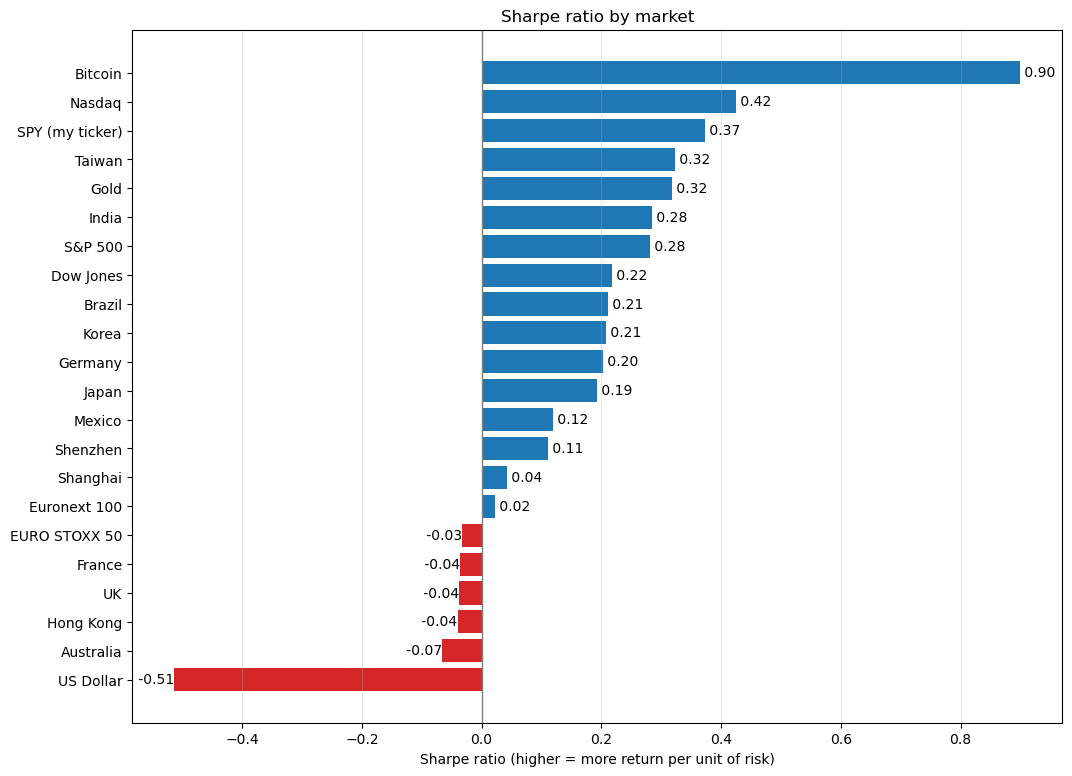

In [4]:
# ==========================================
# Sharpe Ratio Comparing with Global Market
# ==========================================

# ----- Markets to compare (removed the duplicate ticker) -----
names = {
    "^DJI": "Dow Jones", "^GSPC": "S&P 500", "^IXIC": "Nasdaq",
    "^HSI": "Hong Kong", "000001.SS": "Shanghai", "399001.SZ": "Shenzhen",
    "^N225": "Japan", "^FTSE": "UK", "^GDAXI": "Germany", "^TWII": "Taiwan",
    "^MXX": "Mexico", "^BVSP": "Brazil", "GC=F": "Gold", "DX-Y.NYB": "US Dollar",
    "BTC-USD": "Bitcoin", "^AXJO": "Australia", "^KS11": "Korea", "^FCHI": "France",
    "^STOXX50E": "EURO STOXX 50", "^N100": "Euronext 100", "^BSESN": "India",
}

# Add my ticker to the list automatically , skips it if it's already there
all_names = dict(names)
if ticker.upper() not in all_names:
    all_names[ticker.upper()] = f"{ticker.upper()} (my ticker)"
    
prices = yf.download(list(all_names), start=twenty_yrs_ago, end=today, interval="1d")["Close"]
prices = prices.rename(columns=all_names)    

# ----- Work out yearly numbers for each market, using its own history -----
rf = 0.05 
rows = {}

# skip anything with data less than 1 year
for col in prices.columns:
    s = prices[col].dropna()
    if len(s) < 250:
        continue

    r = s.pct_change().dropna()
    years = (s.index[-1] - s.index[0]).days / 365
    # about 252 for stocks, 365 for Bitcoin
    days_per_year = len(r) / years
    # compound yearly return
    cagr = (s.iloc[-1] / s.iloc[0]) ** (1 / years) - 1
    # yearly risk
    vol = r.std() * np.sqrt(days_per_year)

    rows[col] = {
        "Start": s.index[0].date(),
        "Years": years,
        "Return / yr": cagr,
        "Risk / yr": vol,
        "Sharpe Ratio": (r.mean() * days_per_year - rf) / vol,
        "Max drawdown": (s / s.cummax() - 1).min(),
    }

statistics = pd.DataFrame(rows).T
num_cols = ["Years", "Return / yr", "Risk / yr", "Sharpe Ratio", "Max drawdown"]
statistics[num_cols] = statistics[num_cols].astype(float)
statistics = statistics.sort_values("Sharpe Ratio", ascending=False)
display(statistics.round(3))

# Sharpe ratio bar chart 
plot_data = statistics["Sharpe Ratio"].sort_values()          # lowest to highest, so best ends up on top
colors = ["tab:red" if v < 0 else "tab:blue" for v in plot_data]   # red = negative Sharpe

plt.figure(figsize=(12, 9))
bars = plt.barh(plot_data.index, plot_data.values, color=colors)

for bar, value in zip(bars, plot_data.values):
    plt.text(value, bar.get_y() + bar.get_height() / 2,
             f" {value:.2f}", va="center", ha="left" if value >= 0 else "right", fontsize=10)

plt.axvline(0, color="grey", linewidth=1)
plt.xlabel("Sharpe ratio (higher = more return per unit of risk)")
plt.title("Sharpe ratio by market")
plt.grid(True, axis="x", alpha=0.3)
plt.show()

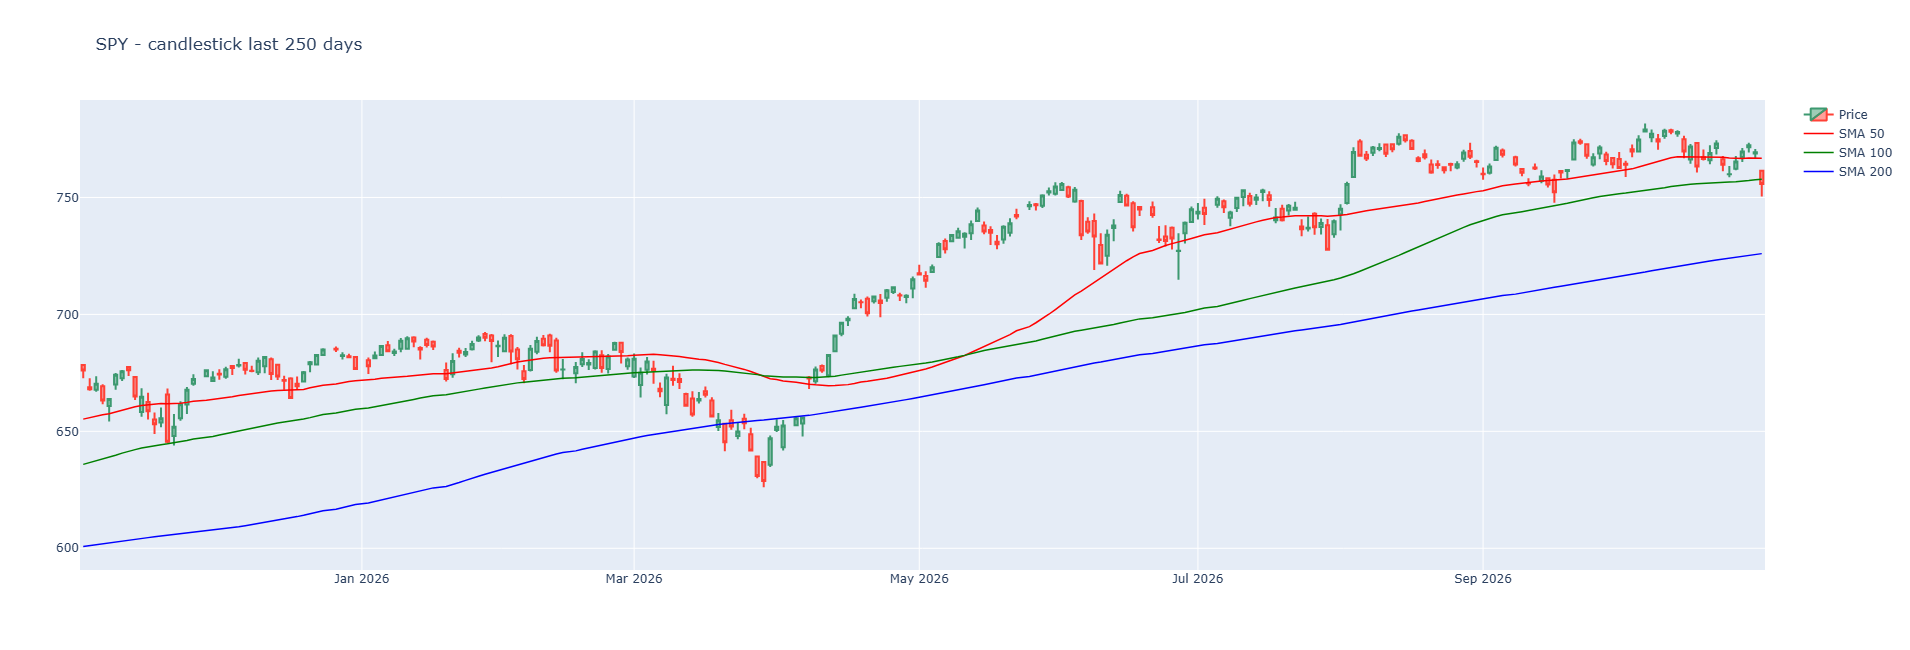

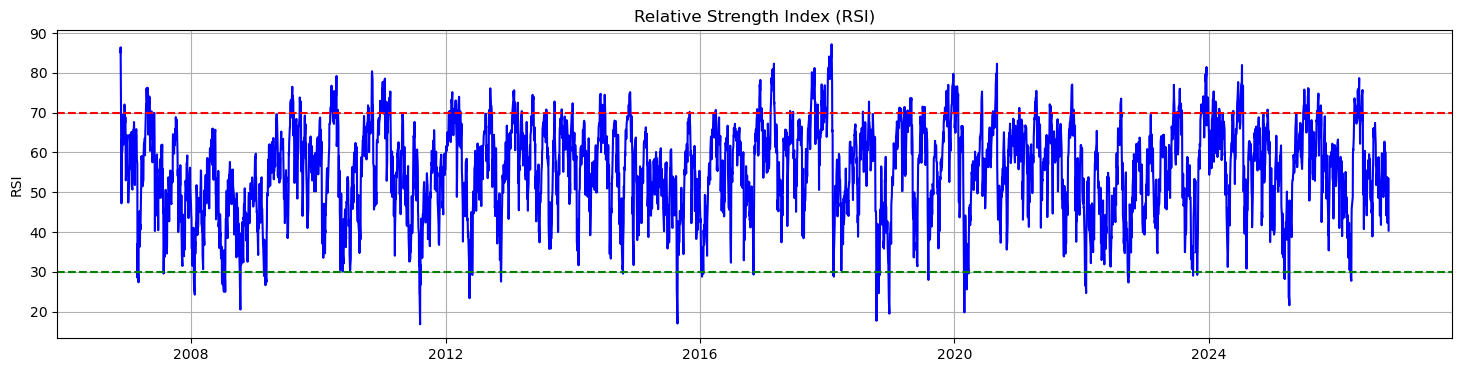

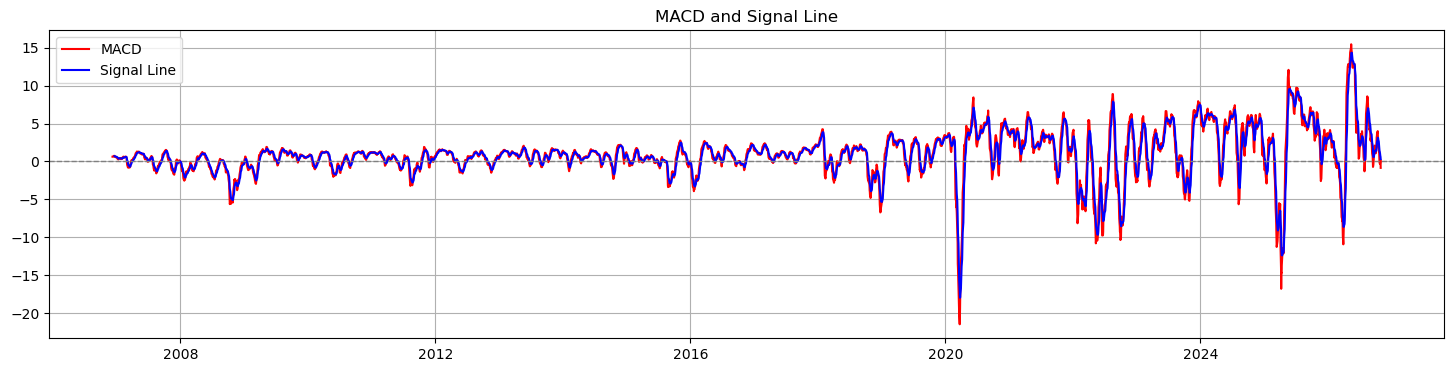

Brick Size is 7.55719970703125


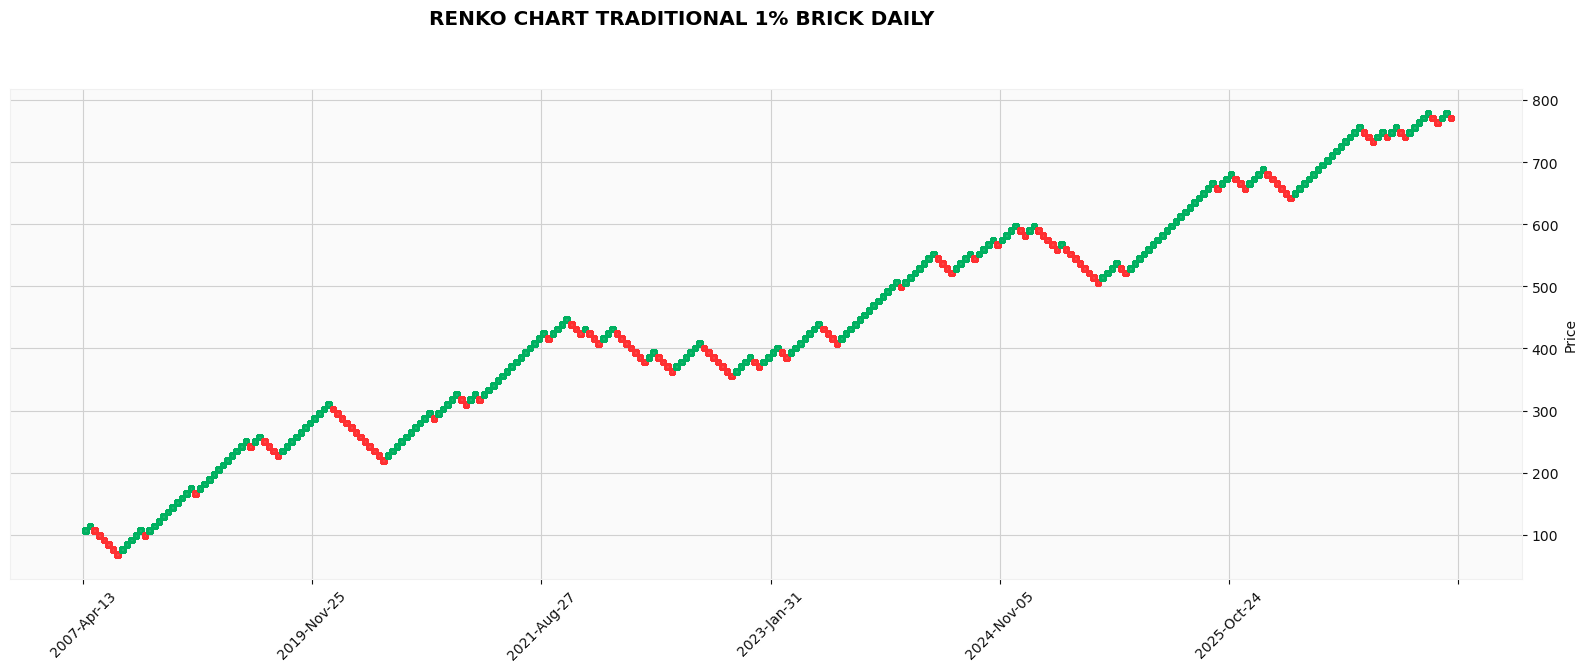

In [5]:
# ==========================================
# Visualisation
# ==========================================
#about 1 year
chart = george_soros.tail(250) 
fig = go.Figure()
#the candles
fig.add_trace(go.Candlestick(x=chart.index, open=chart["Open"], high=chart["High"], low=chart["Low"], close=chart["Close"], name="Price"))
# The moving averages
for col, color in [("SMA 50", "red"), ("SMA 100", "green"), ("SMA 200", "blue")]:
    fig.add_trace(go.Scatter(x=chart.index, y=chart[col], name=col, line=dict(color=color, width=1.5)))
#hide the small slider under the chart
fig.update_layout(title=f"{ticker.upper()} - candlestick last 250 days", xaxis_rangeslider_visible=False, height=650)
#remove weekend gaps
fig.update_xaxes(rangebreaks=[dict(bounds=["sat", "mon"])]) 
fig.show()

plt.figure(figsize=(18,4))
plt.plot(george_soros.index, george_soros['RSI'], color='blue')
plt.axhline(70, color='red', linestyle='--')  #Overbrought
plt.axhline(30, color='green', linestyle='--')  # Oversold
plt.title('Relative Strength Index (RSI)')
plt.ylabel('RSI')
plt.grid(True)
plt.show()

plt.figure(figsize=(18,4))
plt.plot(george_soros.index, george_soros['MACD'], label='MACD', color='red')
plt.plot(george_soros.index, george_soros['MACD Signal'], label='Signal Line', color='blue')
plt.axhline(0, color='grey', linewidth=1, linestyle='--')
plt.title('MACD and Signal Line')
plt.legend()
plt.grid(True)
plt.show()

# ==========================================
# Renko Brick
# ==========================================
a= george_soros['Close'].iloc[-1]*0.01
print('Brick Size is',a)

fplt.plot(george_soros,type='renko',
          renko_params=dict(brick_size=a),
          style='yahoo',
          figsize=(21,7),
          title = "RENKO CHART TRADITIONAL 1% BRICK DAILY")

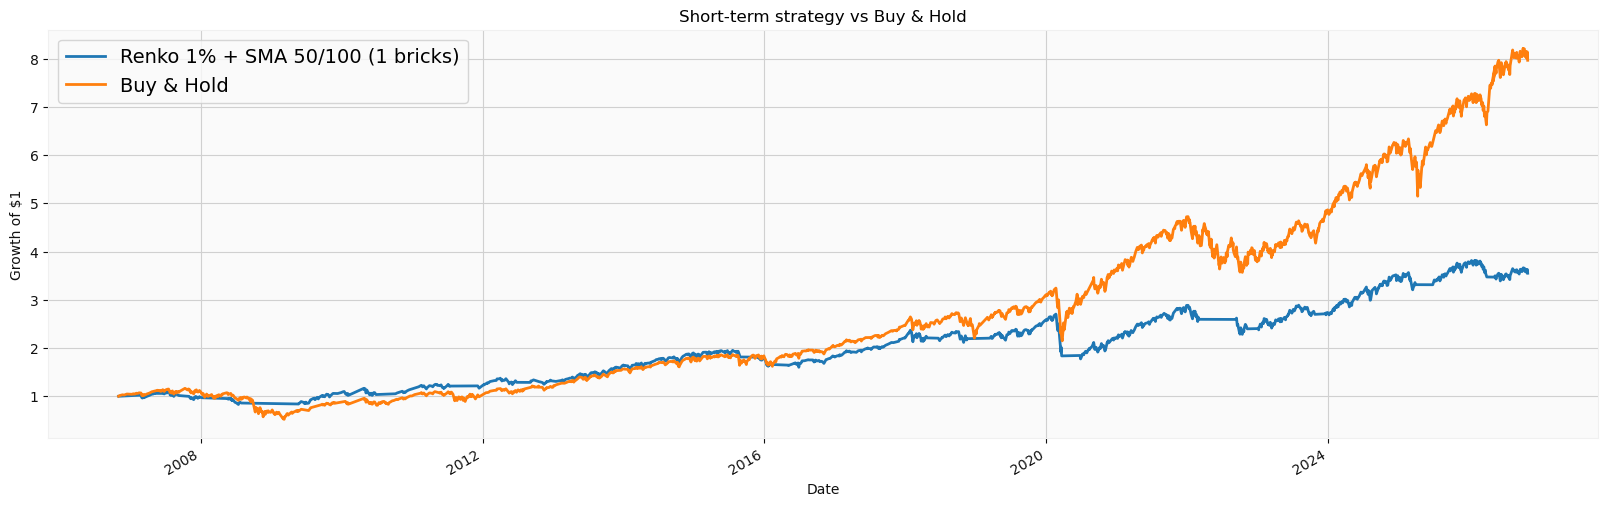

,Total return,CAGR,Max drawdown,Sharpe,Trades
1 brick(s),2.550,0.066,-0.344,0.550,35.0
2 brick(s),2.058,0.058,-0.344,0.492,35.0
3 brick(s),2.882,0.070,-0.344,0.588,29.0
Buy & Hold,6.964,0.110,-0.552,0.632,1.0


In [6]:
#===================================================================================================
#BACK TEST STRATGEDY BUY WHEN 1 BRICK GO UP & SMA 50 > 100 SELL WHEN 1 BRICK GO DOWN  & SMA 50 < 100
#====================================================================================================

#Setting
BRICK_PCT  = 0.01    # brick size = 1% of price
BRICKS_NUM = 1       # need this many bricks in a row before buying/selling
COST       = 0.001   # 0.1% cost every time we buy or sell


def compute_renko_streak(close, brick_pct=0.01):
    streak = np.zeros(len(close))
    last_brick_price = close.iloc[0]
    count = 0

    for i in range(1, len(close)):
        price = close.iloc[i]

        while True:
            brick_size = last_brick_price * brick_pct
            diff = price - last_brick_price
            #up brick
            if diff >= brick_size:    
                last_brick_price += brick_size
                count = count + 1 if count > 0 else 1
            #down brick    
            elif diff <= -brick_size:           
                last_brick_price -= brick_size
                count = count - 1 if count < 0 else -1
            else:
                break

        streak[i] = count

    return streak

def backtest_renko(data, brick_pct, min_bricks, fast="SMA 50", slow="SMA 100"):
    
    streak = compute_renko_streak(data["Close"], brick_pct)
    buy  = ((data[fast] > data[slow]) & (streak >=  min_bricks)).values
    sell = ((data[fast] < data[slow]) & (streak <= -min_bricks)).values

    position = np.zeros(len(data))
    pos = 0
    for i in range(len(data)):
        if buy[i]:
            pos = 1
        elif sell[i]:
            pos = 0
        position[i] = pos

    position = pd.Series(position, index=data.index)
    daily_return = data["Close"].pct_change()
    trades = position.diff().abs().fillna(0)

    net = daily_return * position.shift(1) - COST * trades
    net = net.fillna(0)
    return net,position

def summarize(r):
    equity = (1 + r).cumprod()
    years = len(r) / 252
    n = {
        "Total return": equity.iloc[-1] - 1,
        "CAGR": equity.iloc[-1] ** (1 / years) - 1,
        "Max drawdown": (equity / equity.cummax() - 1).min(),
        "Sharpe": np.sqrt(252) * r.mean() / r.std(),
    }
    
    return n

# ----- Run backtest and plot -----
net, position = backtest_renko(george_soros, BRICK_PCT, BRICKS_NUM)
buy_hold_ret = george_soros["Close"].pct_change().fillna(0)

plt.figure(figsize=(20, 6))
(1 + net).cumprod().plot(label=f"Renko {BRICK_PCT:.0%} + SMA 50/100 ({BRICKS_NUM} bricks)", linewidth=2)
(1 + buy_hold_ret).cumprod().plot(label="Buy & Hold", linewidth=2)
plt.title("Short-term strategy vs Buy & Hold")
plt.ylabel("Growth of $1")
plt.legend(fontsize=14)
plt.grid(True)
plt.show()

# ----- Compare 1, 2, 3 bricks and buy & hold in one table -----
rows = {}
for n in [1, 2, 3]:
    r, p = backtest_renko(george_soros, BRICK_PCT, n)
    rows[f"{n} brick(s)"] = {**summarize(r), "Trades": int(p.diff().abs().sum())}
rows["Buy & Hold"] = {**summarize(buy_hold_ret), "Trades": 1}

display(pd.DataFrame(rows).T.round(3))

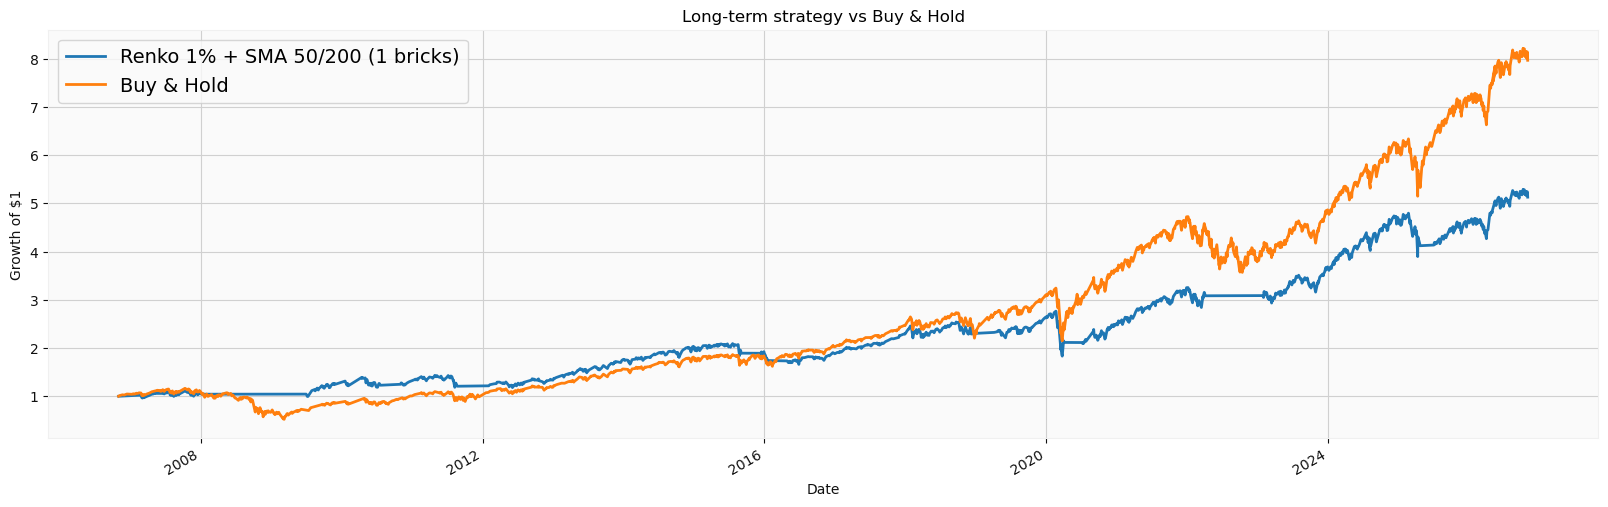

,Total return,CAGR,Max drawdown,Sharpe,Trades
1 brick(s),4.127,0.085,-0.337,0.656,19.0
2 brick(s),3.678,0.080,-0.337,0.620,19.0
3 brick(s),3.373,0.077,-0.337,0.592,19.0
Buy & Hold,6.964,0.110,-0.552,0.632,1.0


In [7]:
#===================================================================================================
#BACK TEST STRATGEDY BUY WHEN 1 BRICK GO UP & SMA 50 > 200 SELL WHEN 1 BRICK GO DOWN  & SMA 50 < 200
#====================================================================================================
def backtest_renko(data, brick_pct, min_bricks, fast="SMA 50", slow="SMA 200"):
    
    streak = compute_renko_streak(data["Close"], brick_pct)
    buy  = ((data[fast] > data[slow]) & (streak >=  min_bricks)).values
    sell = ((data[fast] < data[slow]) & (streak <= -min_bricks)).values

    position = np.zeros(len(data))
    pos = 0
    for i in range(len(data)):
        if buy[i]:
            pos = 1
        elif sell[i]:
            pos = 0
        position[i] = pos

    position = pd.Series(position, index=data.index)
    daily_return = data["Close"].pct_change()
    trades = position.diff().abs().fillna(0)

    # yesterday's position earns today's return, minus trading cost
    net = daily_return * position.shift(1) - COST * trades
    net = net.fillna(0)
    return net , position

def summarize(r):
    equity = (1 + r).cumprod()
    years = len(r) / 252
    n = {
        "Total return": equity.iloc[-1] - 1,
        "CAGR": equity.iloc[-1] ** (1 / years) - 1,
        "Max drawdown": (equity / equity.cummax() - 1).min(),
        "Sharpe": np.sqrt(252) * r.mean() / r.std(),
    }    
    return n

# ----- Run backtest then plot-----
net, position = backtest_renko(george_soros, BRICK_PCT, BRICKS_NUM)
buy_hold_ret = george_soros["Close"].pct_change().fillna(0)

plt.figure(figsize=(20, 6))
(1 + net).cumprod().plot(label=f"Renko {BRICK_PCT:.0%} + SMA 50/200 ({BRICKS_NUM} bricks)", linewidth=2)
(1 + buy_hold_ret).cumprod().plot(label="Buy & Hold", linewidth=2)
plt.title("Long-term strategy vs Buy & Hold")
plt.ylabel("Growth of $1")
plt.legend(fontsize=14)
plt.grid(True)
plt.show()

# ----- Compare 1, 2, 3 bricks and buy & hold in one table -----
rows = {}
for n in [1, 2, 3]:
    r, p = backtest_renko(george_soros, BRICK_PCT, n)
    rows[f"{n} brick(s)"] = {**summarize(r), "Trades": int(p.diff().abs().sum())}
rows["Buy & Hold"] = {**summarize(buy_hold_ret), "Trades": 1}

display(pd.DataFrame(rows).T.round(3))

In [ ]:
# ==========================================
# Neural Prophet
# ==========================================

from neuralprophet import NeuralProphet
import pandas as pd

# Convert index to datetime
george_soros.index = pd.to_datetime(george_soros.index)

# Create dataframe
futures = george_soros[['Close']].reset_index()
futures.columns = ['ds', 'y']

# Remove duplicates
futures = futures.drop_duplicates(subset='ds')

# Sort dates
futures = futures.sort_values('ds')

# Optional: remove timezone
futures['ds'] = futures['ds'].dt.tz_localize(None)

# Create model
model = NeuralProphet(
    daily_seasonality=False,  # turn off daily seasonality — too noisy for long-term
    weekly_seasonality=True,
    yearly_seasonality=True,
    n_changepoints=10
)

# IMPORTANT: specify frequency
model.fit(futures, freq='D')

# Future dataframe
future = model.make_future_dataframe(futures, periods=200)

forecast = model.predict(future)
actual_prediction = model.predict(futures)

plt.figure(figsize=(21,6))
plt.plot(actual_prediction['ds'] , actual_prediction['yhat1'] , label = "Actual Prediction" , c = 'r',linewidth=1)
future_only = forecast[forecast['ds'] > futures['ds'].max()].copy()
plt.plot(future_only['ds'], future_only['yhat1'], label='Future Prediction', c='b',linewidth=1)
plt.plot(futures['ds'] , futures['y'] , label = 'Track Record' , c = 'g')
plt.title("Price Preditction By Neural Prophet")
plt.legend()
plt.show()

Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.
WARNING - (NP.forecaster.fit) - When Global modeling with local normalization, metrics are displayed in normalized scale.
INFO - (NP.df_utils._infer_frequency) - Major frequency B corresponds to 96.282% of the data.
INFO - (NP.df_utils._infer_frequency) - Defined frequency is equal to major frequency - D
INFO - (NP.config.init_data_params) - Setting normalization to global as only one dataframe provided for training.
INFO - (NP.config.set_auto_batch_epoch) - Auto-set batch_size to 64
INFO - (NP.config.set_auto_batch_epoch) - Auto-set epochs to 70


Training: |          | 0/? [00:00<?, ?it/s]

WARNING - (NP.config.set_lr_finder_args) - Learning rate finder: The number of batches (79) is too small than the required number                     for the learning rate finder (242). The results might not be optimal.

Finding best initial lr: 100%|██████████| 242/242 [00:02<00:00, 84.54it/s]


Epoch 29:  41%|████▏     | 29/70 [00:00<00:00, 9664.29it/s] n_loss=0.0041, reg_loss=0.000, MAE=23.40, RMSE=31.70, Loss=0.0041, RegLoss=0.000]  

In [ ]:
# ==========================================
# Features engineering
# ==========================================

# --- log return ---
george_soros['LogReturn']    = np.log(george_soros['Close'] / george_soros['Close'].shift(5))
george_soros['Future_Return'] = george_soros['LogReturn'].shift(-5)
threshold = 0
george_soros['Up'] = np.where(
    george_soros['Future_Return'] > threshold, 1,
    np.where(george_soros['Future_Return'] < -threshold, 0, np.nan)
)

# --- join vix data ---
vix = yf.Ticker("^VIX")
vix_data = vix.history(start=twenty_yrs_ago, end=today, interval='1d')
vix_data = vix_data[['Close']].rename(columns={'Close': 'VIX'})
george_soros.index = george_soros.index.tz_localize(None).normalize()
vix_data.index = vix_data.index.tz_localize(None).normalize()
george_soros["VIX"] = vix_data["VIX"].reindex(george_soros.index, method="ffill")
df = george_soros.copy()

# ---features engineering---
df['ret_1d']  = df['Close'].pct_change(1)
df['ret_5d']  = df['Close'].pct_change(5)
df['ret_20d'] = df['Close'].pct_change(20)
df['ret_60d'] = df['Close'].pct_change(60)

df['rsi_norm']       = (df['RSI'] - 50) / 50
df['macd_hist']      = df['MACD'] - df['MACD Signal']

df['gap'] = df['Open'] / df['Close'].shift(1) - 1

df['price_vs_sma50'] = df['Close'] / df['SMA 50'] - 1
df['sma100_vs_sma200'] = df['SMA 100'] / df['SMA 200'] - 1
df['above_sma200'] = (df['Close'] > df['SMA 200']).astype(int)

df['vol_ratio']      = df['Volume'] / df['Volume'].rolling(20).mean()
df['rolling_vol']    = df['ret_1d'].rolling(10).std()
df['vol_short_vs_long'] = df['ret_1d'].rolling(10).std() / df['ret_1d'].rolling(60).std()

df['vix_level']      = df['VIX']
df['vix_z']        = (df['VIX'] - df['VIX'].rolling(252).mean()) / df['VIX'].rolling(252).std()
df['vix_change_5d'] = df['VIX'].pct_change(5)

df['bb_mid'] = df['Close'].rolling(20).mean()
df['bb_std'] = df['Close'].rolling(20).std()
df['bb_upper'] = df['bb_mid'] + 2*df['bb_std']
df['bb_lower'] = df['bb_mid'] - 2*df['bb_std']
df['bb_width']     = (df['bb_upper'] - df['bb_lower']) / df['bb_mid']
df['bb_position'] = (
    (df['Close'] - df['bb_lower']) /
    (df['bb_upper'] - df['bb_lower'])
)

atr = ta.volatility.AverageTrueRange(
    high=df['High'],
    low=df['Low'],
    close=df['Close']
)
df['atr'] = atr.average_true_range()
df['atr_pct'] = df['atr']/df['Close']

df['high_20'] = df['High'].rolling(20).max()
df['low_20'] = df['Low'].rolling(20).min()
df['dist_high_20'] = df['Close'] / df['high_20'] - 1
df['dist_low_20']  = df['Close'] / df['low_20']  - 1
df['dist_high_252'] = df['Close'] / df['High'].rolling(252).max() - 1

print(df.isna().sum())
print("Total rows:", len(df))

In [ ]:
# =================================================================================================
# Machine Learning Model Deployment (Logistic Regression , Random Forest, XGBoost, Neural Network)
# =================================================================================================
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

# ----- Feature sets -----
all_features = ["ret_1d", "ret_5d", "ret_20d", "ret_60d", "rsi_norm", "macd_hist", "gap",
                "price_vs_sma50", "sma100_vs_sma200", "above_sma200", "vol_ratio",
                "rolling_vol", "vol_short_vs_long", "vix_level", "vix_z", "vix_change_5d",
                "bb_mid", "bb_std", "bb_upper", "bb_lower", "bb_width", "bb_position", 
                "atr", "atr_pct", "high_20", "low_20", "dist_high_20", "dist_low_20", 
                "dist_high_252"]

feature_sets = {
    
    "Logistic": ["ret_5d", "ret_20d", "rsi_norm", "sma100_vs_sma200", "atr_pct", 
                 "vol_short_vs_long", "vix_z", "vix_change_5d", "dist_high_252"],
    
    "Random Forest": ["ret_5d", "ret_20d", "ret_60d", "rsi_norm", "bb_position", "price_vs_sma50",
                      "sma100_vs_sma200", "above_sma200", "atr_pct", "vol_short_vs_long",
                      "vix_level", "vix_z", "vix_change_5d", "dist_high_252"],
    
    "XGBoost":       ["ret_5d", "ret_20d", "ret_60d", "rsi_norm", "macd_hist", "sma100_vs_sma200",
                      "above_sma200", "atr_pct", "vol_short_vs_long", "vix_level", "vix_change_5d",
                      "dist_high_252", "gap"],
    
    "Neural Network": ["ret_5d", "ret_20d", "rsi_norm", "sma100_vs_sma200", "atr_pct", 
                   "vol_short_vs_long", "vix_z", "vix_change_5d", "dist_high_252"]
}

# ----- Clean data -----
data = df[all_features + ["Up"]].replace([np.inf, -np.inf], np.nan).dropna()
y = data["Up"].astype(int)
print("Rows used:", len(data))

# ----- Models -----
models = {
    "Logistic": Pipeline([("sc", StandardScaler()), ("m", LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000))]),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=4, min_samples_leaf=100, class_weight="balanced", random_state=0, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, min_child_weight=50,  scale_pos_weight=(y == 0).sum() / (y == 1).sum(), eval_metric="logloss", random_state=0, n_jobs=-1),
    "Neural Network": Pipeline([("sc", StandardScaler()), ("m", MLPClassifier(hidden_layer_sizes=(16, 8),  alpha=0.1, max_iter=200, random_state=0))]),
}

# ----- Test each model: its own set vs all features -----
# ----- Settings -----
BUY_LEVEL  = 0.5     # BUY  if P(up) is above this
SELL_LEVEL = 0.5     # SELL if P(up) is below this
COST       = 0.001   # 0.1% cost each time we buy or sell

def to_signal(p):
    if p > BUY_LEVEL:
        return "BUY"
    if p < SELL_LEVEL:
        return "SELL"
    return "HOLD"

# ----- Newest day with complete data  -----
latest = df[all_features].replace([np.inf, -np.inf], np.nan).dropna().iloc[[-1]]
as_of = latest.index[0]

# ----- Test each model, save its historical predictions, then predict the newest day -----
cv = TimeSeriesSplit(n_splits=5, gap=5)      # gap=5 because the target looks 5 days ahead
rows = []
oos_probs = {}                               # historical P(up) for each model, for the backtest

for name, model in models.items():
    for set_name, cols in [("own set", feature_sets[name]), ("all features", all_features)]:
        X = data[cols]
        label = f"{name} | {set_name}"

        # 1. Historical test: predict each period using only earlier data
        oos = pd.Series(np.nan, index=data.index)
        aucs = []
        for tr, te in cv.split(X):
            model.fit(X.iloc[tr], y.iloc[tr])
            p = model.predict_proba(X.iloc[te])[:, 1]
            oos.iloc[te] = p
            aucs.append(roc_auc_score(y.iloc[te], p))
        oos_probs[label] = oos

        # 2. Live prediction: retrain on ALL history, then predict the newest day
        model.fit(X, y)
        p_up = model.predict_proba(latest[cols])[0, 1]

        row = {"Model": name, "Features": set_name}
        for i, a in enumerate(aucs):
            row[f"Period {i+1}"] = a
        row["Average AUC"] = np.mean(aucs)
        row["P(up)"] = p_up
        row["Signal"] = to_signal(p_up)
        rows.append(row)

table = pd.DataFrame(rows).set_index(["Model", "Features"])

print(f"Data as of close: {as_of.date()}")
print(f"Prediction covers: the next 5 trading days (to about {(as_of + pd.offsets.BDay(5)).date()})")
display(table.round(3))
print(f"Models saying BUY: {(table['Signal'] == 'BUY').sum()} of {len(table)}")


# ==========================================
# BACKTEST: trade each model's historical signals
# ==========================================

# Return from today's close to tomorrow's close
next_ret = df["Close"].shift(-1) / df["Close"] - 1

def backtest_probs(p_up):
    """Turn P(up) into positions (1 = invested, 0 = cash) and daily net returns."""
    p_up = p_up.dropna()
    pos = 0
    positions = []
    for p in p_up:
        if p > BUY_LEVEL:
            pos = 1
        elif p < SELL_LEVEL:
            pos = 0
        positions.append(pos)              # in between = keep yesterday's position

    position = pd.Series(positions, index=p_up.index)
    trades = position.diff().abs().fillna(position.iloc[0])
    net = (position * next_ret.reindex(position.index) - COST * trades).dropna()
    return net, position

def summarize(r):
    equity = (1 + r).cumprod()
    years = len(r) / 252
    return {
        "Total return": equity.iloc[-1] - 1,
        "CAGR": equity.iloc[-1] ** (1 / years) - 1,
        "Max drawdown": (equity / equity.cummax() - 1).min(),
        "Sharpe": np.sqrt(252) * r.mean() / r.std() if r.std() > 0 else np.nan,
    }

# Extra strategy: average the P(up) of all 8 models
oos_probs["All models (average)"] = pd.concat(list(oos_probs.values()), axis=1).mean(axis=1)

bt_rows = {}
curves = {}
for label, p in oos_probs.items():
    net, position = backtest_probs(p)
    bt_rows[label] = {**summarize(net),
                      "Time invested": position.mean(),
                      "Trades": int(position.diff().abs().sum())}
    curves[label] = (1 + net).cumprod()

# Buy & hold over exactly the same test days
test_days = curves["All models (average)"].index
bh = next_ret.reindex(test_days).dropna()
bt_rows["Buy & Hold"] = {**summarize(bh), "Time invested": 1.0, "Trades": 1}
curves["Buy & Hold"] = (1 + bh).cumprod()

bt_table = pd.DataFrame(bt_rows).T.sort_values("Sharpe", ascending=False)
print(f"\nBacktest period: {test_days[0].date()} to {test_days[-1].date()}   |   cost per trade: {COST:.2%}")
display(bt_table.round(3))

# ----- Chart: each model's own set + average + buy & hold -----
plt.figure(figsize=(18, 7))
to_plot = [l for l in curves if "own set" in l] + ["All models (average)", "Buy & Hold"]
for label in to_plot:
    curves[label].plot(label=label,
                       linewidth=3 if label in ("Buy & Hold", "All models (average)") else 1.5,
                       color="black" if label == "Buy & Hold" else None)
plt.title("ML strategies vs Buy & Hold (out-of-sample)")
plt.ylabel("Growth of $1")
plt.legend(fontsize=11)
plt.grid(True)
plt.show()
plt.show()